# Lab 7 – Deep Learning Laboratory
## Text Classification with Word Embeddings and Bidirectional LSTM

This notebook implements a complete Deep Learning solution for the SMS Spam Collection binary classification problem using a Bidirectional LSTM in TensorFlow/Keras.

## Task 1 – Load and Explore the Dataset

In [1]:
import os
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

# Set random seeds for reproducibility as required
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("NumPy and TensorFlow random seeds set to 42.")

TensorFlow version: 2.21.0
NumPy and TensorFlow random seeds set to 42.


In [2]:
# Download the SMS Spam Collection dataset from UCI Repository
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam_collection.zip"
extract_dir = "sms_spam_data"

print("Downloading dataset...")
urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# Read the raw dataset file
data_file = os.path.join(extract_dir, "SMSSpamCollection")
df = pd.read_csv(data_file, sep='\t', names=['label', 'message'])

# Display dataset information
print("\n--- Dataset Shape ---")
print(df.shape)

print("\n--- Dataset Info ---")
df.info()

print("\n--- First 5 Rows ---")
display(df.head())


--- Dataset Shape ---
(5572, 2)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

--- First 5 Rows ---


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
# Check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Count the number of spam and ham messages
class_counts = df['label'].value_counts()
print("\nClass counts:")
print(class_counts)

# Calculate message lengths (number of characters)
df['message_length'] = df['message'].apply(len)

print("\n--- Message Length Statistics ---")
print(f"Minimum length: {df['message_length'].min()}")
print(f"Maximum length: {df['message_length'].max()}")
print(f"Average length: {df['message_length'].mean():.2f}")

Missing values in each column:
label      0
message    0
dtype: int64

Class counts:
label
ham     4825
spam     747
Name: count, dtype: int64

--- Message Length Statistics ---
Minimum length: 2
Maximum length: 910
Average length: 80.49


In [4]:
# Display one example of each class
ham_example = df[df['label'] == 'ham'].iloc[0]['message']
spam_example = df[df['label'] == 'spam'].iloc[0]['message']

print("--- Example of Ham (Not Spam) ---")
print(ham_example)
print("\n--- Example of Spam ---")
print(spam_example)

--- Example of Ham (Not Spam) ---
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

--- Example of Spam ---
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


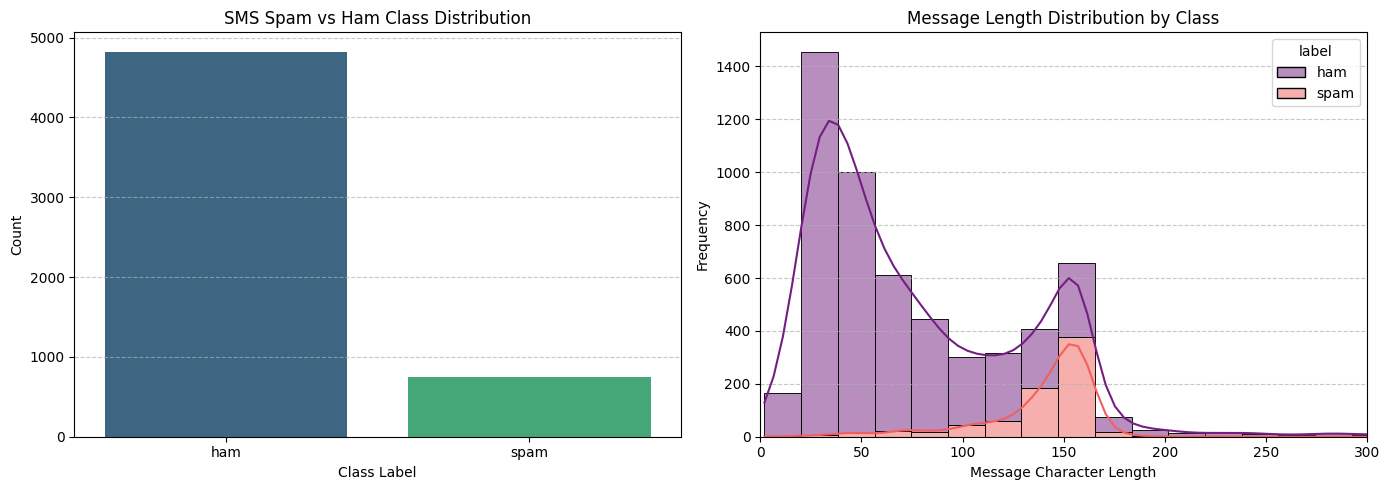

In [5]:
# Plotting distribution visualizations
plt.figure(figsize=(14, 5))

# 1. Class Distribution Bar Plot
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='label', hue='label', palette='viridis', legend=False)
plt.title('SMS Spam vs Ham Class Distribution')
plt.xlabel('Class Label')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 2. Message Length Distribution Histogram
plt.subplot(1, 2, 2)
sns.histplot(data=df, x='message_length', hue='label', bins=50, kde=True, palette='magma', multiple='stack')
plt.title('Message Length Distribution by Class')
plt.xlabel('Message Character Length')
plt.ylabel('Frequency')
plt.xlim(0, 300)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## Task 2 – Preprocess the Text

In [6]:
from sklearn.model_selection import train_test_split

# 1. Convert labels to numerical values (spam = 1, ham = 0)
df['label_numeric'] = df['label'].map({'ham': 0, 'spam': 1})

# 2. Separate messages and labels
X = df['message'].values
y = df['label_numeric'].values

# 3 & 4. Split dataset into Train (80%), Val (10%), Test (10%) using Stratified Splitting
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("Training Set shape:", X_train.shape, y_train.shape)
print("Validation Set shape:", X_val.shape, y_val.shape)
print("Testing Set shape:", X_test.shape, y_test.shape)

print(f"\nTrain Class Ratio (Spam): {y_train.mean():.4f}")
print(f"Val Class Ratio (Spam): {y_val.mean():.4f}")
print(f"Test Class Ratio (Spam): {y_test.mean():.4f}")

Training Set shape: (4457,) (4457,)
Validation Set shape: (557,) (557,)
Testing Set shape: (558,) (558,)

Train Class Ratio (Spam): 0.1342
Val Class Ratio (Spam): 0.1329
Test Class Ratio (Spam): 0.1344


In [7]:
# 5, 6, 7 & 8. TextVectorization and Padding
VOCAB_SIZE = 10000
MAX_SEQUENCE_LENGTH = 100

vectorizer = TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_sequence_length=MAX_SEQUENCE_LENGTH,
    output_mode='int'
)

# Adapt the vectorizer using training data ONLY to prevent data leakage
vectorizer.adapt(X_train)

# Transform inputs to padded sequences
X_train_seq = vectorizer(X_train)
X_val_seq = vectorizer(X_val)
X_test_seq = vectorizer(X_test)

print("Padded Train sequences shape:", X_train_seq.shape)
print("Padded Val sequences shape:", X_val_seq.shape)
print("Padded Test sequences shape:", X_test_seq.shape)

Padded Train sequences shape: (4457, 100)
Padded Val sequences shape: (557, 100)
Padded Test sequences shape: (558, 100)


## Task 3 – Build the Model

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dropout, Dense

EMBEDDING_DIM = 64
LSTM_UNITS = 64

# Build architecture: Embedding -> Bidirectional LSTM -> Dropout -> Dense
model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, input_length=MAX_SEQUENCE_LENGTH, name="Embedding"),
    Bidirectional(LSTM(LSTM_UNITS), name="Bidirectional_LSTM"),
    Dropout(0.5, name="Dropout"),
    Dense(1, activation='sigmoid', name="Output")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Bidirectional_LSTM              │ ?                      │   0 (unbuilt) │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Task 3 Explanations:

* **Why Bidirectional LSTM produces an output width of 2 × units:**
A regular forward LSTM processes the sequence in one direction, producing outputs matching the unit count (64 dimensions). A Bidirectional LSTM processes the sequence forward and backward simultaneously using two distinct LSTM structures, then concatenates their respective outputs. Consequently, the output space dimension is exactly doubled (`2 * 64 = 128`).

In [9]:
# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## Task 4 – Train and Evaluate

In [10]:
# Train the model
EPOCHS = 10
BATCH_SIZE = 32

history = model.fit(
    X_train_seq,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_seq, y_val)
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 17s 98ms/step - accuracy: 0.9156 - loss: 0.2272 - val_accuracy: 0.9820 - val_loss: 0.0654
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 98ms/step - accuracy: 0.9881 - loss: 0.0477 - val_accuracy: 0.9820 - val_loss: 0.0819
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 98ms/step - accuracy: 0.9926 - loss: 0.0286 - val_accuracy: 0.9838 - val_loss: 0.0711
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 96ms/step - accuracy: 0.9964 - loss: 0.0135 - val_accuracy: 0.9856 - val_loss: 0.0597
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.9993 - loss: 0.0047 - val_accuracy: 0.9874 - val_loss: 0.0675
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 96ms/step - accuracy: 0.9996 - loss: 0.0029 - val_accuracy: 0.9874 - val_loss: 0.0742
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 98ms/step - accuracy: 0.9998 - loss: 0.0013 - val_accuracy: 0.9874 - val_loss: 0.0811
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 96ms/step - accuracy: 0.9998 - loss: 9.9498e-0

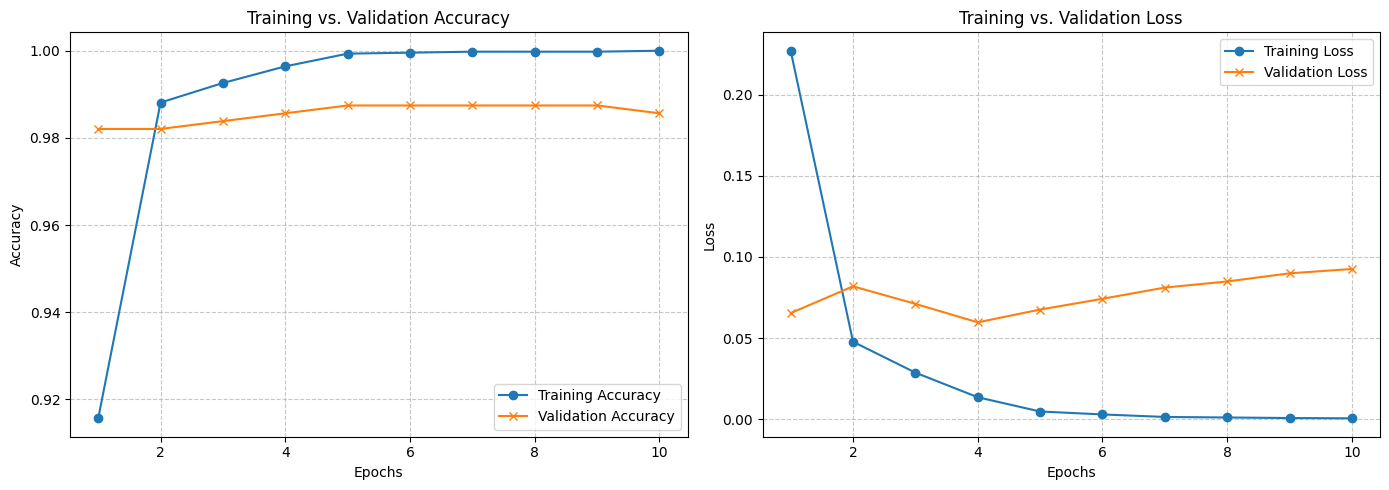

In [11]:
# Plot training and validation loss/accuracy
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy', marker='x')
plt.title('Training vs. Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['loss'], label='Training Loss', marker='o')
plt.plot(epochs_range, history.history['val_loss'], label='Validation Loss', marker='x')
plt.title('Training vs. Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9857 - loss: 0.0694

Test Loss: 0.0694
Test Accuracy: 0.9857
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step


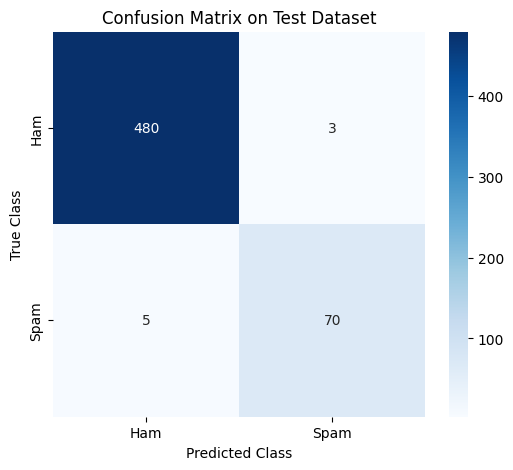


--- Classification Report ---
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       483
        Spam       0.96      0.93      0.95        75

    accuracy                           0.99       558
   macro avg       0.97      0.96      0.97       558
weighted avg       0.99      0.99      0.99       558



In [12]:
from sklearn.metrics import classification_report, confusion_matrix

# Evaluate on test dataset
test_loss, test_accuracy = model.evaluate(X_test_seq, y_test, verbose=1)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

y_pred_prob = model.predict(X_test_seq)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Confusion Matrix on Test Dataset')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.show()

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))

## Task 5 – Predict New Text

In [13]:
def predict(text):
    processed_seq = vectorizer([text])
    prediction_prob = model.predict(processed_seq)[0][0]
    predicted_class = "Spam" if prediction_prob > 0.5 else "Ham"
    confidence = prediction_prob if prediction_prob > 0.5 else (1 - prediction_prob)

    print(f"Message: '{text}'")
    print(f"Predicted Label: {predicted_class} (Confidence: {confidence:.2%})\n")
    return predicted_class, confidence

# Run predictions on five distinct sample messages
test_messages = [
    "URGENT! Your mobile number has been awarded a £2000 prize! Call 09058094507 now to claim. T&Cs apply.",
    "Hi mom, I will be home late tonight for dinner. Please save some food for me!",
    "FREE RINGTONE text 'LIVE' to 80082 right now to secure yours for free.",
    "Hey, are we still playing football this weekend? Let me know.",
    "Your verification code is 49204. If you did not request this, ignore this email."
]

for msg in test_messages:
    predict(msg)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Message: 'URGENT! Your mobile number has been awarded a £2000 prize! Call 09058094507 now to claim. T&Cs apply.'
Predicted Label: Spam (Confidence: 99.97%)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Message: 'Hi mom, I will be home late tonight for dinner. Please save some food for me!'
Predicted Label: Ham (Confidence: 100.00%)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Message: 'FREE RINGTONE text 'LIVE' to 80082 right now to secure yours for free.'
Predicted Label: Spam (Confidence: 99.82%)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Message: 'Hey, are we still playing football this weekend? Let me know.'
Predicted Label: Ham (Confidence: 100.00%)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Message: 'Your verification code is 49204. If you did not request this, ignore this email.'
Predicted Label: Ham (Confidence: 99.98%)



## Summary Report

### 1. Why is padding needed?
TensorFlow models perform computations via matrix multiplications, which require tensors of static dimension lengths. Since input messages naturally vary in length, sequences are formatted using padding (adding trailing zeros) or truncation to fit a uniform input size (e.g., 100 features) without altering semantic structure.

### 2. Why are embeddings better than one-hot encoding?
One-hot arrays are extremely high-dimensional, sparse vectors that do not capture any semantic relationships between different words. Embedding layers map vocabularies into lower-dimensional dense vectors where related words share localized spatial proximities, allowing the network to capture contextual similarity.

### 3. Why does Bidirectional LSTM help?
Unlike unidirectional Recurrent Neural Networks, Bidirectional LSTMs parse elements of sequences forward and backward. This permits the network to inspect contextual dependencies coming from both the past and the future of any given token simultaneously, facilitating better text context understanding.

### 4. Why did we choose the output layer and loss function?
For binary classification tasks, predicting a probability boundary between 0 and 1 requires a single dense unit mapped with a `sigmoid` activation. The optimal loss model for adjusting output probabilities in binary target datasets is `binary_crossentropy`, which penalizes inaccurate predictions exponentially.

### 5. Why is accuracy misleading for imbalanced data, and what other metrics did we use?
In heavily imbalanced situations, predicting the majority class exclusively yields high accuracy scores despite completely failing to classify rare targets. Hence, we analyze metrics like **Precision** (purity of true predictions), **Recall** (capacity to find actual spam elements), and **F1-Score** (harmonic mean of Precision and Recall).